In [ ]:
import numpy as np

# binario de palace y guardado de los resultados
# reemplazar por la ubicación verdadera del binario
PALACE_BIN = '/home/ruiz/repo/spack/opt/spack/linux-zen3/palace-develop-blpbtxe43ne2or3yo7gou6ycmdwdxuzl/bin/palace'
OUTDIR     = "."

# parámetros de barrido
FREQ_START_GHZ = 4.5
FREQ_END_GHZ   = 5.5
N_POINTS       = 6001 # nº de puntos REPORTADOS en la curva. Con el barrido adaptativo
                      # (abajo) esto NO son solves completos: es post-proceso barato, se
                      # puede subir sin costo de solver. Sin el barrido adaptativo, sí es
                      # un solve completo por punto -> carísimo.

# parámetros de simulación

# --- barrido ADAPTIVO de frecuencia (modelo de orden reducido / PROM) ---
# OJO: NO es mallado adaptativo. Es cómo Palace evita un solve completo en cada
# frecuencia: hace unos pocos solves completos en frecuencias elegidas
# automáticamente, arma un modelo reducido y evalúa el resto casi gratis.
# Hay que activarlo a mano en el JSON (celda de más abajo) porque SQDMetal
# todavía no lo expone.
ADAPTIVE_TOL         = 1e-5 # tolerancia del error del modelo reducido; más chico = más muestras
ADAPTIVE_MAX_SAMPLES = 30   # tope de solves completos si el modelo no converge antes

SOLVER_ORDER          = 2 # orden de las funciones base del solver. 2 es más preciso pero ~6-8x
                          # los grados de libertad (y la memoria) para el mismo mallado.
SOLVER_TOL            = 1e-6 # parámetro de convergencia, mientras más pequeño, más convergencia necesita para proceder
SOLNS_TO_SAVE         = 0 # número de frecuencias para las cuales guardar las distribuciones espaciales de campo. Recomiendo no guardar porque sino te ocupa todo el disco duro (probar con pocas frecuencias)
NUM_CPUS              = 8 # número de núcleos a usar en la simulación, averiguar ejecutando nproc en la terminal (linux)

# mallado: la única pauta es usar el mínimo mallado que permita resolver los detalles finos del diseño
BG_MAX_SIZE_UM        = 200.0 # máximo tamaño de los elementos de fondo
RESONATOR_MIN_SIZE_UM = 6.0 # mínimo tamaño utilizado en el mallado del resonador
TL_MIN_SIZE_UM        = 40.0 # mínimo tamaño utilizado en la línea de transmisión
# no tiene mucho sentido definir un TL_MAX_SIZE_UM, al final el programa termina utilizando el menor entre todos los máximos tamaños declarados.

In [2]:
from build_design import build_design
# me armo el diseño desde otro archivo .py, lo creamos en esta sesión
design = build_design()
design.rebuild()
print("components:", list(design.components.keys()))


components: ['LP1', 'LP2', 'TL', 'otg1', 'stg2', 'resonator1']


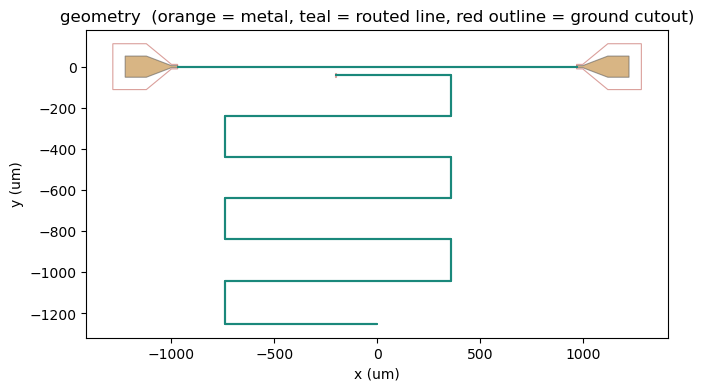

In [3]:
import matplotlib.pyplot as plt

# made by claude
def plot_design(design, ax=None, figsize=(9, 4)):
    """Static matplotlib view of a qiskit-metal design, straight from its
    qgeometry tables (mm). Headless-safe -- no Qt / MetalGUI needed.
    For an interactive view use:  from qiskit_metal import MetalGUI; MetalGUI(design)
    """
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    for tname, table in design.qgeometry.tables.items():
        for _, row in table.iterrows():
            try:
                geom = row["geometry"]
                sub = bool(row.get("subtract", False))
                if geom.geom_type == "LineString":
                    xs, ys = geom.xy
                    ax.plot([x * 1e3 for x in xs], [y * 1e3 for y in ys],
                            color="#1a887b", lw=1.5, solid_capstyle="round")
                    continue
                parts = geom.geoms if geom.geom_type.startswith("Multi") else [geom]
                for pp in parts:
                    xs, ys = pp.exterior.xy
                    ax.fill([x * 1e3 for x in xs], [y * 1e3 for y in ys],
                            facecolor="none" if sub else "#b9791f",
                            edgecolor="#bd524a" if sub else "#555",
                            alpha=0.55, lw=0.8)
            except Exception:
                pass
    ax.set_aspect("equal"); ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)")
    ax.set_title("geometry  (orange = metal, teal = routed line, red outline = ground cutout)")
    return ax

ax = plot_design(design)

# vale la pena aumentar las dimensiones del chip: si no hay suficiente espacio entre el diseño y los bordes de la simulación pueden surgir errores

In [4]:
from SQDMetal.PALACE.Frequency_Driven_Simulation import PALACE_Driven_Simulation

driven_options = {
    "dielectric_material": "silicon", # material del sustrato
    "solns_to_save": SOLNS_TO_SAVE,
    "solver_order": SOLVER_ORDER,
    "solver_tol": SOLVER_TOL,
    "solver_maxits": 200, # "número de intentos" que tiene el solver de en terminar un paso, si se excede vuelve a empezar
    "solver_initial_guess": True, # para cada frecuencia si es que utilizo la solución obtenida para la frecuencia anterior para resolver la nueva
    "fillet_resolution": 12, # que tanto resuelve el mallado las curvas, un valor mayor requiere mayor número de elementos
    "palace_dir": PALACE_BIN,
    "num_cpus": NUM_CPUS
}

driven_sim = PALACE_Driven_Simulation(
    name="s21_test",
    metal_design=design,
    sim_parent_directory=OUTDIR,
    mode="simPC", # siempre dejo esto así
    meshing="GMSH", # lo mismo, que software utiliza para hacer el mallado. Gmsh es el default en sqdmetal
    user_options=driven_options,
    create_files=True, # si es que solo quieres revisar el valor de los modos no necesitas esto, esto define si se guardan los archivos o no
)


In [5]:
driven_sim.add_metallic(1) # registramos la capa 1 de qiskit (la default) como superficie metálica
driven_sim.add_ground_plane()

# creamos los puertos de entrada en cada launchpad (solo en este tipo de simulaciones, no se tienen que colocar en eigenmode)
# el "coaxial" que drivea en el sistema se modela como una condición de contorno en los launchpads
# esta condición de contorno es una cinta (de 20 micrones en este caso) que conecta el launchpad con el plano de masa
# es importante que esta longitud cubra la brecha entre el conductor central del launchpad y el plano de tierra.

driven_sim.create_port_CPW_on_Launcher("LP1", 20e-6)  
driven_sim.create_port_CPW_on_Launcher("LP2", 20e-6)

# definimos cual es el puerto que driveamos, se definen por orden de creación y arrancan de 1
# por tanto estamos driveando LP1
driven_sim.set_port_excitation(1)


In [6]:
# elementos que tienen un mallado distinto al de los elementos de fondo
driven_sim.fine_mesh_components(
    ["resonator1"],
    min_size=RESONATOR_MIN_SIZE_UM * 1e-6, max_size =BG_MAX_SIZE_UM * 1e-6,
    taper_dist_min= 3 * RESONATOR_MIN_SIZE_UM *1e-6, metals_only=False,
    taper_dist_max = 5 * RESONATOR_MIN_SIZE_UM *1e-6
)
driven_sim.fine_mesh_components(
    ["TL", "LP1", "LP2"],
    min_size=TL_MIN_SIZE_UM * 1e-6, 
    taper_dist_min= 2 * TL_MIN_SIZE_UM *1e-6, metals_only=False,
    taper_dist_max = 5 * TL_MIN_SIZE_UM *1e-6
)
# taper dist se define de la siguiente manera:
"""
Va a haber un conjunto de elementos que van a pertener (por ejemplo) al resonador. Estos van a tener un mallado fino que conforme uno se va alejando de este van a ir aumentando de tamaño hasta el máximo tamaño que especificaste. El taper min te da la mínima distancia en el que este cambio de tamaño ocurre: todos los elementos a una distancia menor al resonador tendrán el mínimo tamaño. El taper max te da la distancia máxima de esta zona de transición: todos los elementos más lejos que esta distancia tendrán el tamaño máximo (salvo que haya otro componente de mallado fino)
"""

'\nVa a haber un conjunto de elementos que van a pertener (por ejemplo) al resonador. Estos van a tener un mallado fino que conforme uno se va alejando de este van a ir aumentando de tamaño hasta el máximo tamaño que especificaste. El taper min te da la mínima distancia en el que este cambio de tamaño ocurre: todos los elementos a una distancia menor al resonador tendrán el mínimo tamaño. El taper max te da la distancia máxima de esta zona de transición: todos los elementos más lejos que esta distancia tendrán el tamaño máximo (salvo que haya otro componente de mallado fino)\n'

In [7]:
freq_start = FREQ_START_GHZ * 1e9
freq_end   = FREQ_END_GHZ * 1e9
freq_step  = (freq_end - freq_start) / max(N_POINTS - 1, 1)

driven_sim.set_freq_values(freq_start=freq_start, freq_end=freq_end, freq_step=freq_step)
driven_sim.prepare_simulation() # después de ejecutar fijarse en el s21_test.png y el s21_test.msh para ver si el mallado tiene sentido!!

# el proceso de mallado es single core, no hay forma de paralelizarlo.
# usualmente si tarde más de ~2 min es porque quizás estás usando un mallado demasiado fino y no tendrás suficiente espacio en memoria para resolver el problema

# suele tirar el error
# Error   : Gmsh has not been initialized
# Error   : Gmsh has not been initialized
# pero es benigno, no hay de que preocuparse

Error   : Gmsh has not been initialized
Error   : Gmsh has not been initialized


In [9]:
# --- activar el barrido rápido de frecuencia (PROM) ---
# SQDMetal no expone AdaptiveTol / AdaptiveMaxSamples, así que se escriben a
# mano en el JSON de Palace, DESPUÉS de prepare_simulation() (que crea el
# archivo) y ANTES de run().
#
# Sin esto, Palace resuelve el sistema completo en CADA uno de las N_POINTS
# frecuencias (p. ej. 1001 solves -> horas). Con esto hace ~5-30 solves
# completos en frecuencias elegidas por el algoritmo, arma el modelo reducido
# y evalúa las N_POINTS casi gratis.
import json

cfg_path = driven_sim._sim_config
with open(cfg_path) as f:
    cfg = json.load(f)
cfg["Solver"]["Driven"]["AdaptiveTol"] = ADAPTIVE_TOL
cfg["Solver"]["Driven"]["AdaptiveMaxSamples"] = ADAPTIVE_MAX_SAMPLES
with open(cfg_path, "w") as f:
    json.dump(cfg, f, indent=2)

# verificación: el bloque Driven ahora tiene que contener AdaptiveTol
print(json.dumps(cfg["Solver"]["Driven"], indent=2))
assert "AdaptiveTol" in cfg["Solver"]["Driven"], "el patch NO se aplicó"

# al ejecutar run(), en el log tiene que aparecer
#   'Adaptive sampling converged with N frequency samples'
# y NO 'It k/1001' repetido -> eso confirma que el PROM está activo.
# (si volvés a correr prepare_simulation(), volvé a correr esta celda: la
#  re-genera el archivo y se pierde el patch)

{
  "MinFreq": 4.5,
  "MaxFreq": 5.5,
  "FreqStep": 0.001,
  "SaveStep": 0,
  "AdaptiveTol": 1e-05,
  "AdaptiveMaxSamples": 30
}


In [10]:
driven_sim.run() # ejecutamos la simulación

# MUY IMPORTANTE: 
"""
El programa genera el mallado antes de ejecutar la simulación y hace estimaciones del problema a resolver

Antes de proceder con la simulación revisar bien el número de elementos de mallado el número de incógnitas y la memoria estimada para la simulación

Esta última usualmente es la memoria consumida por cada core, así que el estimado en realidad hay que multiplicarlo por el número de núcleos utilizado.

Sin embargo muchas veces el pico de memoria es más alto que el que reporta este estimado: si estás muy justo de memoria, vale la pena ir monitoreando la ram utilizada para que no se te cuelgue la máquina.

Mi consejo: dejá ejecutar el inicio de la simulación hasta que genere el archivo .msh, luego revisarlo (en gmsh) y ver si el mallado es suficiente para resolver los detalles del diseño. En caso negativo, reducir el tamaño de los elementos. En caso positivo, ver que no esté demasiado fino para que la memoria no explote. Es cuestión de práctica y un poco de prueba y error.

Mientras se va ejecutando el solver va a ir guardando las soluciones 
"""
# el pico de memoria con estos parámetros fue de 11GB en total

>> /usr/bin/mpirun -n 8 /home/ruiz/repo/spack/opt/spack/linux-zen3/palace-develop-blpbtxe43ne2or3yo7gou6ycmdwdxuzl/bin/palace-x86_64.bin s21_test.json

_____________     _______
_____   __   \____ __   /____ ____________
____   /_/  /  __ ` /  /  __ ` /  ___/  _ \
___   _____/  /_/  /  /  /_/  /  /__/  ___/
  /__/     \___,__/__/\___,__/\_____\_____/


--> Warning!
Output folder is not empty; program will overwrite content! (outputFiles)
Git changeset ID: 3b8c020
Running with 8 MPI processes
Device configuration: cpu
Memory configuration: host-std
libCEED backend: /cpu/self/xsmm/blocked

Added 533 elements in 2 iterations of local bisection for under-resolved interior boundaries
Added 10568 duplicate vertices for interior boundaries in the mesh
Added 26791 duplicate boundary elements for interior boundaries in the mesh
Added 1712 boundary elements for material interfaces to the mesh

Characteristic length and time scales:
 Lc = 4.800e-03 m, tc = 1.601e-02 ns
Finished partitioning mesh 

'\nEl programa genera el mallado antes de ejecutar la simulación y hace estimaciones del problema a resolver\n\nAntes de proceder con la simulación revisar bien el número de elementos de mallado el número de incógnitas y la memoria estimada para la simulación\n\nEsta última usualmente es la memoria consumida por cada core, así que el estimado en realidad hay que multiplicarlo por el número de núcleos utilizado.\n\nSin embargo muchas veces el pico de memoria es más alto que el que reporta este estimado: si estás muy justo de memoria, vale la pena ir monitoreando la ram utilizada para que no se te cuelgue la máquina.\n\nMi consejo: dejá ejecutar el inicio de la simulación hasta que genere el archivo .msh, luego revisarlo (en gmsh) y ver si el mallado es suficiente para resolver los detalles del diseño. En caso negativo, reducir el tamaño de los elementos. En caso positivo, ver que no esté demasiado fino para que la memoria no explote. Es cuestión de práctica y un poco de prueba y error.\

|S21| min: -0.66 dB at 5.500000 GHz


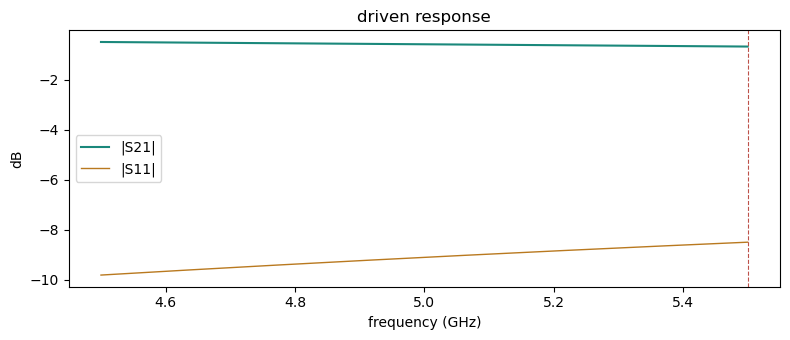

In [11]:
import matplotlib.pyplot as plt

s = driven_sim.retrieve_data()
freqs = np.asarray(s["freqs"])
S21 = np.asarray(s["S21"])
S11 = np.asarray(s.get("S11"))

s21_db = 20 * np.log10(np.abs(S21))
i = int(np.argmin(s21_db))
print(f"|S21| min: {s21_db[i]:.2f} dB at {freqs[i] / 1e9:.6f} GHz")
if i in (0, len(freqs) - 1):
    print("WARNING: minimum at a band edge -- the resonance is probably outside the swept window")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(freqs / 1e9, s21_db, color="#1a887b", label="|S21|")
if S11 is not None and S11.size:
    ax.plot(freqs / 1e9, 20 * np.log10(np.abs(S11)), color="#b9791f", lw=1, label="|S11|")
ax.axvline(freqs[i] / 1e9, color="#bd524a", ls="--", lw=0.8)
ax.set_xlabel("frequency (GHz)"); ax.set_ylabel("dB"); ax.legend()
ax.set_title("driven response")
plt.tight_layout()
